# Análisis de anomalías: cómo hackear un modelo para mejorarlo
**Hacking Game · IP San Sebastián** — Fernando Pinto Montecinos

Filtro de spam con **TF-IDF + regresión logística**. Lo entrenamos, lo atacamos entre todos y usamos sus errores
(las anomalías) para mejorarlo.

> ⚠️ Los datos son **simulados** (1.000 correos en español generados con plantillas). Los resultados son una
> demostración, no una medición del mundo real.

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

plt.rcParams["figure.figsize"] = (9, 4)
pd.set_option("display.max_colwidth", 120)

## 1. Los datos

In [2]:
df = pd.read_csv("../data/correos_es.csv")
df["spam"] = (df["etiqueta"] == "spam").astype(int)
print(df.shape)
print(df["etiqueta"].value_counts())
df.sample(8, random_state=1)

(1000, 3)
etiqueta
normal    600
spam      400
Name: count, dtype: int64


,texto,etiqueta,spam
507,¡Felicidades! Participas en el sorteo de un iphone. Ingresa ahora: http://dzvk2c.link/pago Sin costo para ti.,spam,1
818,¡Enhorabuena! Fuiste seleccionado para recibir un bono de $50.000. Responde YA: bit.ly/spbx55 Oferta válida por tiem...,spam,1
452,Revisa el comprobante de la transferencia del jueves: www.bonoaamf.net,spam,1
368,"Quedan cupos limitados para el taller de estadística del jueves, inscríbete con Diego.",normal,0
242,Urgente Ignacio: necesito la planilla de Python antes de las 17:00.,normal,0
929,Revisa el comprobante de la transferencia del viernes: http://tinyurl.com/tnaj6e3,spam,1
262,"Matías, ¿me puedes mandar la presentación de ventas antes del domingo?",normal,0
810,"Camila, ¿me puedes mandar la presentación de estadística antes del viernes?",normal,0


## 2. ¿Cómo lee una máquina un correo? TF-IDF en 4 pasos
Ejemplo con tres mensajes. Usamos la fórmula de la charla: **TF** = veces que aparece la palabra / total de palabras
del mensaje, **IDF** = log(N / mensajes que contienen la palabra).

In [3]:
mini = ["ganaste premio gratis", "premio gratis ya", "hola mamá llegas almorzar"]

# Paso 1: vocabulario
vocab = sorted({w for m in mini for w in m.split()})
print("Vocabulario:", vocab)

# Paso 2: TF
tf = pd.DataFrame([[m.split().count(w) / len(m.split()) for w in vocab] for m in mini],
                  columns=vocab, index=[f"m{i+1}" for i in range(len(mini))])

# Paso 3: IDF
N = len(mini)
idf = pd.Series({w: np.log(N / sum(w in m.split() for m in mini)) for w in vocab})

# Paso 4: TF × IDF
tfidf_manual = tf * idf
display(tf.round(2)); display(idf.round(2).to_frame("IDF").T); display(tfidf_manual.round(2))

Vocabulario: ['almorzar', 'ganaste', 'gratis', 'hola', 'llegas', 'mamá', 'premio', 'ya']


,almorzar,ganaste,gratis,hola,llegas,mamá,premio,ya
m1,0.00,0.33,0.33,0.00,0.00,0.00,0.33,0.00
m2,0.00,0.00,0.33,0.00,0.00,0.00,0.33,0.33
m3,0.25,0.00,0.00,0.25,0.25,0.25,0.00,0.00


,almorzar,ganaste,gratis,hola,llegas,mamá,premio,ya
IDF,1.1,1.1,0.41,1.1,1.1,1.1,0.41,1.1


,almorzar,ganaste,gratis,hola,llegas,mamá,premio,ya
m1,0.00,0.37,0.14,0.00,0.00,0.00,0.14,0.00
m2,0.00,0.00,0.14,0.00,0.00,0.00,0.14,0.37
m3,0.27,0.00,0.00,0.27,0.27,0.27,0.00,0.00


Esta matriz es lo que recibe el modelo. TF-IDF solo la construye; la regresión logística decide.

## 3. Entrenamiento

Exactitud en test: 100.0%
              precision    recall  f1-score   support

      normal       1.00      1.00      1.00       150
        spam       1.00      1.00      1.00       100

    accuracy                           1.00       250
   macro avg       1.00      1.00      1.00       250
weighted avg       1.00      1.00      1.00       250



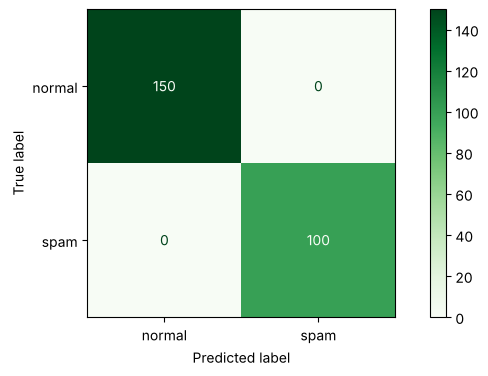

In [4]:
STOPWORDS_ES = ["a","al","algo","ante","antes","aqui","aquí","asi","así","con","como","cual","cuando","de","del",
    "desde","donde","e","el","ella","en","entre","era","es","esa","ese","eso","esta","está","este","esto","fue","ha",
    "hay","la","las","le","les","lo","los","mas","más","me","mi","mis","muy","ni","no","nos","o","para","pero","por",
    "porque","que","qué","se","si","sin","sobre","son","su","sus","te","tu","tus","un","una","uno","y","ya","yo"]

X_train, X_test, y_train, y_test = train_test_split(
    df["texto"], df["spam"], test_size=0.25, random_state=42, stratify=df["spam"])

vectorizer = TfidfVectorizer(lowercase=True, stop_words=STOPWORDS_ES)
Xtr = vectorizer.fit_transform(X_train)
Xte = vectorizer.transform(X_test)

modelo = LogisticRegression(max_iter=1000).fit(Xtr, y_train)
pred = modelo.predict(Xte)
print(f"Exactitud en test: {accuracy_score(y_test, pred):.1%}")
print(classification_report(y_test, pred, target_names=["normal", "spam"]))
ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["normal", "spam"], cmap="Greens");

> **¿100% de exactitud? Desconfía.** Los correos salen de plantillas, así que los de entrenamiento y los de test se
> parecen demasiado. El número no dice nada sobre el mundo real. Por eso, en vez de mirar la métrica, vamos a
> **atacar** el modelo.

## 4. ¿Qué aprendió? Los coeficientes

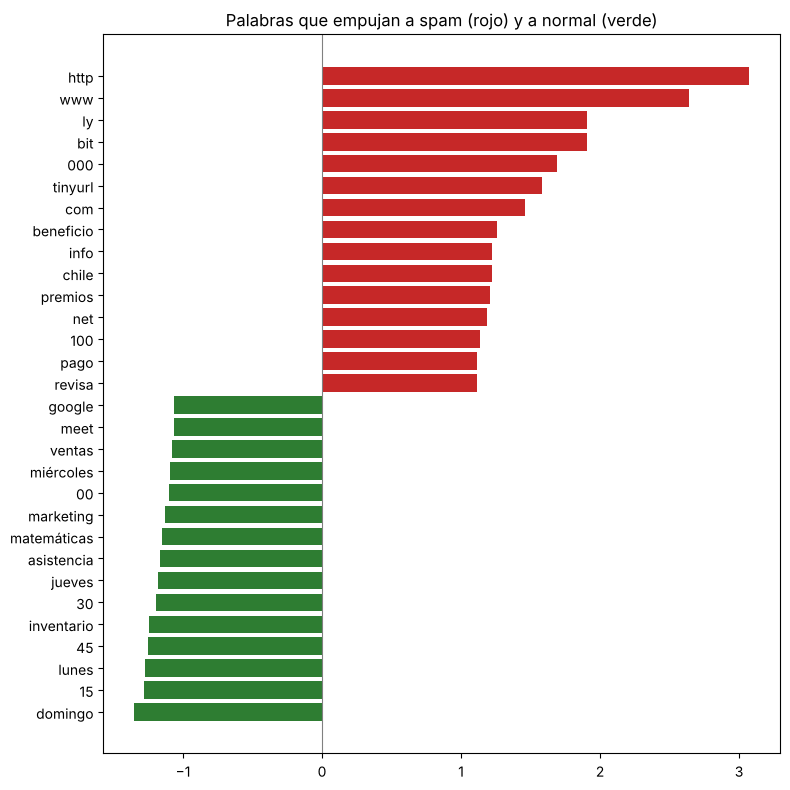

In [5]:
vocabulario = np.array(vectorizer.get_feature_names_out())
coef = modelo.coef_[0]
orden = np.argsort(coef)
top = pd.concat([
    pd.DataFrame({"palabra": vocabulario[orden[-15:]], "coef": coef[orden[-15:]]}),
    pd.DataFrame({"palabra": vocabulario[orden[:15]], "coef": coef[orden[:15]]}),
]).sort_values("coef")

colores = ["#2e7d32" if c < 0 else "#c62828" for c in top["coef"]]
plt.figure(figsize=(8, 8))
plt.barh(top["palabra"], top["coef"], color=colores)
plt.axvline(0, color="grey", lw=0.8)
plt.title("Palabras que empujan a spam (rojo) y a normal (verde)")
plt.tight_layout(); plt.show()

### Nubes de palabras según el peso en el modelo (no según la frecuencia)

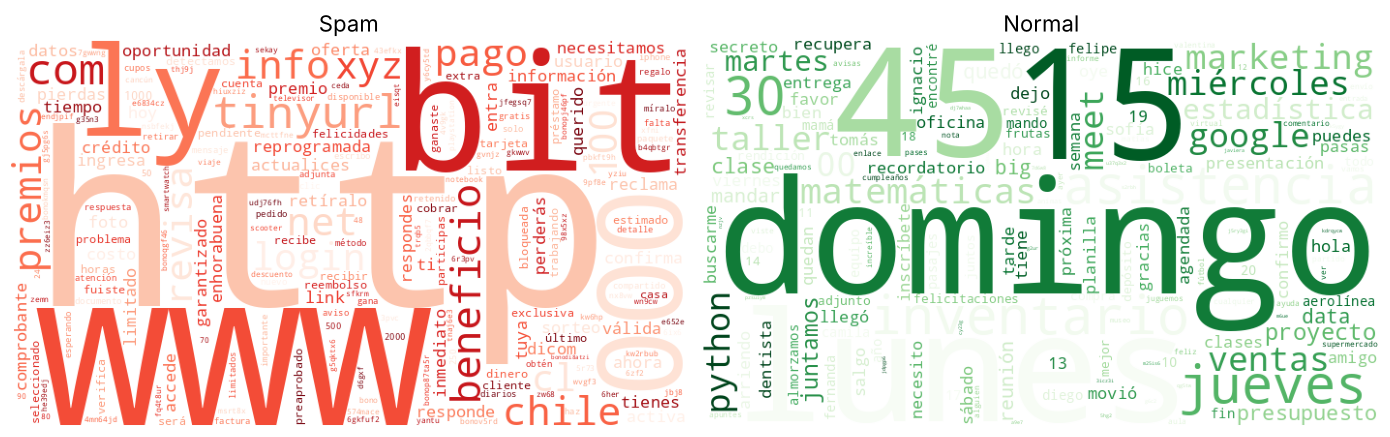

In [6]:
from wordcloud import WordCloud

pesos_spam = {w: c for w, c in zip(vocabulario, coef) if c > 0}
pesos_normal = {w: -c for w, c in zip(vocabulario, coef) if c < 0}

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for a, pesos, titulo, cmap in [(ax[0], pesos_spam, "Spam", "Reds"), (ax[1], pesos_normal, "Normal", "Greens")]:
    wc = WordCloud(width=700, height=400, background_color="white", colormap=cmap).generate_from_frequencies(pesos)
    a.imshow(wc); a.axis("off"); a.set_title(titulo, fontsize=16)
plt.tight_layout(); plt.show()

## 5. Probemos mensajes

In [7]:
def clasificar(texto, top_n=6):
    v = vectorizer.transform([texto])
    p = modelo.predict_proba(v)[0, 1]
    idx = v.nonzero()[1]
    aportes = sorted(zip(vocabulario[idx], v.toarray()[0, idx] * coef[idx]), key=lambda x: -abs(x[1]))[:top_n]
    ignoradas = [w for w in re.findall(r"(?u)\b\w\w+\b", texto.lower())
                 if w not in vectorizer.vocabulary_ and w not in STOPWORDS_ES]
    etiqueta = "🚨 SPAM" if p >= 0.5 else "✅ normal"
    print(f"{etiqueta}  P(spam) = {p:.1%}   →  {texto}")
    print("   aportes:", ", ".join(f"{w} ({a:+.2f})" for w, a in aportes) or "—")
    if ignoradas:
        print("   palabras que el modelo no conoce (las ignora):", ", ".join(ignoradas))
    return p

clasificar("Felicidades, ganaste un premio de $500.000. Reclámalo en bit.ly/premio")
clasificar("Hola Camila, ¿nos juntamos el lunes para revisar el informe?")
clasificar("Hola profe, gracias por la clase de estadística. Pr3m1o para ti en bit.ly/premio");

🚨 SPAM  P(spam) = 88.9%   →  Felicidades, ganaste un premio de $500.000. Reclámalo en bit.ly/premio
   aportes: bit (+0.58), ly (+0.58), premio (+0.53), 000 (+0.42), felicidades (+0.24), ganaste (+0.18)
   palabras que el modelo no conoce (las ignora): reclámalo
✅ normal  P(spam) = 10.6%   →  Hola Camila, ¿nos juntamos el lunes para revisar el informe?
   aportes: lunes (-0.42), juntamos (-0.37), camila (-0.23), informe (-0.18), hola (-0.17), revisar (-0.15)
🚨 SPAM  P(spam) = 52.1%   →  Hola profe, gracias por la clase de estadística. Pr3m1o para ti en bit.ly/premio
   aportes: bit (+0.63), ly (+0.63), estadística (-0.37), clase (-0.37), ti (+0.34), gracias (-0.29)
   palabras que el modelo no conoce (las ignora): profe, pr3m1o


Fíjate en el link: `bit.ly/premio` no se lee como un link. El tokenizador lo parte en `bit`, `ly` y `premio`.
El modelo no sabe qué es una URL; solo ve palabras sueltas. Ese es uno de sus puntos ciegos.

## 6. El reto: análisis de anomalías
Descarga las respuestas del Google Form (**Respuestas → Descargar CSV**), guárdalas como `respuestas_form.csv`
junto a este notebook y ejecuta la celda. Si el archivo no existe, se usan mensajes de ejemplo.

In [8]:
from pathlib import Path

ruta = Path("respuestas_form.csv")
if ruta.exists():
    form = pd.read_csv(ruta)
    col = [c for c in form.columns if "mensaje" in c.lower() or "spam" in c.lower()][0]
    ataques = form[col].dropna().astype(str).tolist()
else:
    ataques = [
        "Hola profe, gracias por la clase. Te dejo un pr3m1o en bit.ly/x9",
        "Camila, el informe de estadística quedó listo. Por cierto gan4ste un b0no en www.b0no.cl",
        "G A N A S T E un premio, entra a bit.ly/ok",
        "Recordatorio reunión lunes 10:00, confirma tu asistencia y retira tu regalo en tinyurl.com/r3g4lo",
        "Felicidades ganaste un iPhone gratis, reclama en bit.ly/iphone",
        "Mamá llego tarde, almorzamos el domingo. Sorteo de $1.000.000 en www.s0rte0.cl",
        "Estimado, su cuenta será bloqueada, verifique en http://banco-seguro.xyz",
        "p.r.e.m.i.o para ti en bit.ly/a1",
    ]

res = pd.DataFrame({"mensaje": ataques})
res["prob_spam"] = modelo.predict_proba(vectorizer.transform(res["mensaje"]))[:, 1]
res["evadio"] = res["prob_spam"] < 0.5
print(f"Intentos: {len(res)} | Evadieron el filtro: {res['evadio'].sum()} ({res['evadio'].mean():.0%})")
res.sort_values("prob_spam")

Intentos: 8 | Evadieron el filtro: 4 (50%)


,mensaje,prob_spam,evadio
3,"Recordatorio reunión lunes 10:00, confirma tu asistencia y retira tu regalo en tinyurl.com/r3g4lo",0.242942,True
0,"Hola profe, gracias por la clase. Te dejo un pr3m1o en bit.ly/x9",0.397410,True
1,"Camila, el informe de estadística quedó listo. Por cierto gan4ste un b0no en www.b0no.cl",0.399747,True
5,"Mamá llego tarde, almorzamos el domingo. Sorteo de $1.000.000 en www.s0rte0.cl",0.494277,True
4,"Felicidades ganaste un iPhone gratis, reclama en bit.ly/iphone",0.792891,False
6,"Estimado, su cuenta será bloqueada, verifique en http://banco-seguro.xyz",0.835519,False
7,p.r.e.m.i.o para ti en bit.ly/a1,0.888546,False
2,"G A N A S T E un premio, entra a bit.ly/ok",0.897270,False


### ¿Por qué se escaparon? Las anomalías

In [9]:
for m in res.loc[res["evadio"], "mensaje"]:
    clasificar(m)
    print()

✅ normal  P(spam) = 39.7%   →  Hola profe, gracias por la clase. Te dejo un pr3m1o en bit.ly/x9
   aportes: bit (+0.71), ly (+0.71), clase (-0.41), gracias (-0.33), dejo (-0.31), hola (-0.17)
   palabras que el modelo no conoce (las ignora): profe, pr3m1o, x9

✅ normal  P(spam) = 40.0%   →  Camila, el informe de estadística quedó listo. Por cierto gan4ste un b0no en www.b0no.cl
   aportes: www (+0.66), estadística (-0.36), cl (+0.36), quedó (-0.32), listo (+0.21), camila (-0.20)
   palabras que el modelo no conoce (las ignora): cierto, gan4ste, b0no, b0no

✅ normal  P(spam) = 24.3%   →  Recordatorio reunión lunes 10:00, confirma tu asistencia y retira tu regalo en tinyurl.com/r3g4lo
   aportes: tinyurl (+0.47), asistencia (-0.37), com (+0.35), lunes (-0.34), 00 (-0.33), recordatorio (-0.25)
   palabras que el modelo no conoce (las ignora): retira, r3g4lo

✅ normal  P(spam) = 49.4%   →  Mamá llego tarde, almorzamos el domingo. Sorteo de $1.000.000 en www.s0rte0.cl
   aportes: 000 (+0.72

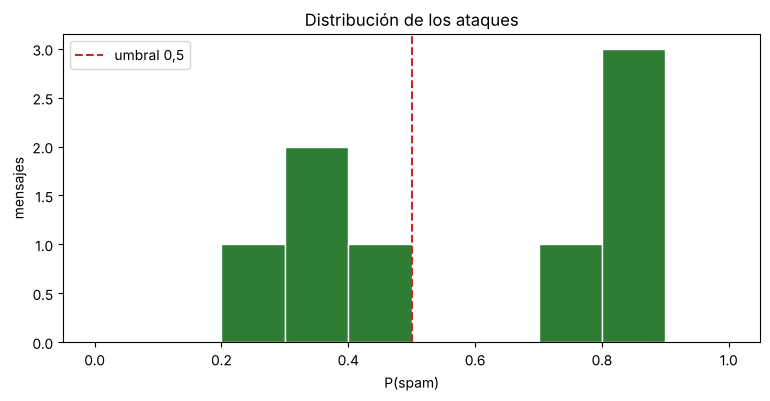

In [10]:
plt.hist(res["prob_spam"], bins=10, range=(0, 1), color="#2e7d32", edgecolor="white")
plt.axvline(0.5, color="#c62828", ls="--", label="umbral 0,5")
plt.xlabel("P(spam)"); plt.ylabel("mensajes"); plt.title("Distribución de los ataques"); plt.legend(); plt.show()

Patrones típicos de evasión:
- **Leetspeak** (`pr3m1o`): palabras que el modelo nunca vio, así que las ignora.
- **Separar letras** (`p.r.e.m.i.o`, `G A N A S T E`): se rompen en tokens de una letra, que se descartan.
- **Diluir** con palabras "normales" (profe, informe, mamá, reunión) que empujan hacia normal.

## 7. Reentrenar con los casos que se escaparon
Agregamos los mensajes que evadieron el filtro, etiquetados como spam, y reentrenamos.

> Ojo: esto **no** demuestra que el modelo aprendió a detectar evasiones en general. Le enseñamos *los casos
> que se escaparon*. Para saber si generaliza, lo probamos con variantes nuevas que no vio.

In [11]:
escapados = res.loc[res["evadio"], "mensaje"].tolist()
X_aug = pd.concat([X_train, pd.Series(escapados)], ignore_index=True)
y_aug = pd.concat([y_train, pd.Series([1] * len(escapados))], ignore_index=True)

vectorizer2 = TfidfVectorizer(lowercase=True, stop_words=STOPWORDS_ES)
modelo2 = LogisticRegression(max_iter=1000).fit(vectorizer2.fit_transform(X_aug), y_aug)

res["prob_spam_v2"] = modelo2.predict_proba(vectorizer2.transform(res["mensaje"]))[:, 1]
print(f"Exactitud en test original con el modelo v2: "
      f"{accuracy_score(y_test, modelo2.predict(vectorizer2.transform(X_test))):.1%}")
res[["mensaje", "prob_spam", "prob_spam_v2"]].round(3).sort_values("prob_spam")

Exactitud en test original con el modelo v2: 100.0%


,mensaje,prob_spam,prob_spam_v2
3,"Recordatorio reunión lunes 10:00, confirma tu asistencia y retira tu regalo en tinyurl.com/r3g4lo",0.243,0.371
0,"Hola profe, gracias por la clase. Te dejo un pr3m1o en bit.ly/x9",0.397,0.491
1,"Camila, el informe de estadística quedó listo. Por cierto gan4ste un b0no en www.b0no.cl",0.400,0.502
5,"Mamá llego tarde, almorzamos el domingo. Sorteo de $1.000.000 en www.s0rte0.cl",0.494,0.567
4,"Felicidades ganaste un iPhone gratis, reclama en bit.ly/iphone",0.793,0.800
6,"Estimado, su cuenta será bloqueada, verifique en http://banco-seguro.xyz",0.836,0.835
7,p.r.e.m.i.o para ti en bit.ly/a1,0.889,0.897
2,"G A N A S T E un premio, entra a bit.ly/ok",0.897,0.903


In [12]:
variantes_nuevas = [
    "Hola equipo, el acta quedó lista. B0n0 especial en bit.ly/zz",
    "r e g a l o para ti en www.r3g4l0.cl",
    "Gracias por venir al taller, pr3mi0 sorpresa en tinyurl.com/q1",
]
pd.DataFrame({
    "mensaje": variantes_nuevas,
    "v1": modelo.predict_proba(vectorizer.transform(variantes_nuevas))[:, 1],
    "v2": modelo2.predict_proba(vectorizer2.transform(variantes_nuevas))[:, 1],
}).round(3)

,mensaje,v1,v2
0,"Hola equipo, el acta quedó lista. B0n0 especial en bit.ly/zz",0.521,0.548
1,r e g a l o para ti en www.r3g4l0.cl,0.861,0.879
2,"Gracias por venir al taller, pr3mi0 sorpresa en tinyurl.com/q1",0.428,0.468


## 8. Defensas y límites
- **Normalizar el texto** antes del modelo (`pr3m1o → premio`, unir letras separadas).
- **Tratar las URL como señal propia** (dominio, acortadores), en vez de partirlas en palabras.
- **Reentrenar con los errores** de forma continua y **monitorear** qué se escapa.
- **Límite de esta demo:** datos simulados y un modelo lineal simple. El atacante siempre puede inventar la
  siguiente variante: es el juego del gato y el ratón.